In [17]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets
from mlscratch.stats.LinearDiscriminantAnalysis import LDA

In [18]:
data = datasets.load_wine()
X = data.data
y = data.target
print(X.shape)
print(y.shape)

(178, 13)
(178,)


## Perform PCA


In [19]:
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X)

In [20]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

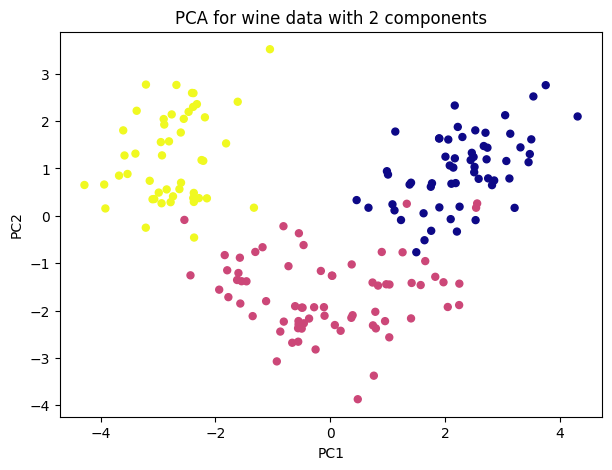

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=[7, 5])

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, s=25, cmap="plasma")
plt.title("PCA for wine data with 2 components")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.savefig("PCA.png")

In [22]:
exp_var = sum(pca.explained_variance_ratio_ * 100)
print("Variance explained:", exp_var)

Variance explained: 55.40633835693528


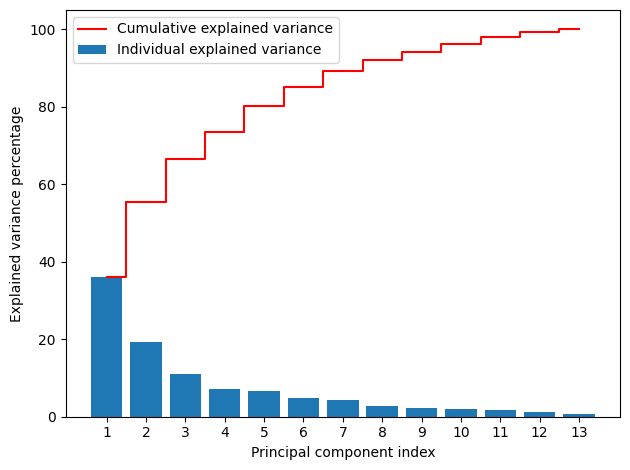

In [23]:
pca = PCA(n_components=None)
X_pca = pca.fit_transform(X_scaled)

exp_var = pca.explained_variance_ratio_ * 100
cum_exp_var = np.cumsum(exp_var)

plt.bar(range(1, 14), exp_var, align="center", label="Individual explained variance")

plt.step(
    range(1, 14),
    cum_exp_var,
    where="mid",
    label="Cumulative explained variance",
    color="red",
)

plt.ylabel("Explained variance percentage")
plt.xlabel("Principal component index")
plt.xticks(ticks=list(range(1, 14)))
plt.legend(loc="best")
plt.tight_layout()

plt.savefig("Barplot_PCA.png")

## Perform LDA
Feature standardization is not needed for LDA as it does not have any effect on the performance of the LDA model.


In [24]:
lda = LDA(n_components=2)
lda.fit(X_scaled, y)
X_lda = lda.transform(X_scaled)

print("Shape of X:", X_scaled.shape)
print("Shape of transformed X:", X_lda.shape)
print(f"Explained variance: {lda._get_explained_variance()}")

Shape of X: (178, 13)
Shape of transformed X: (178, 2)
Explained variance: [0.68747889 0.31252111]


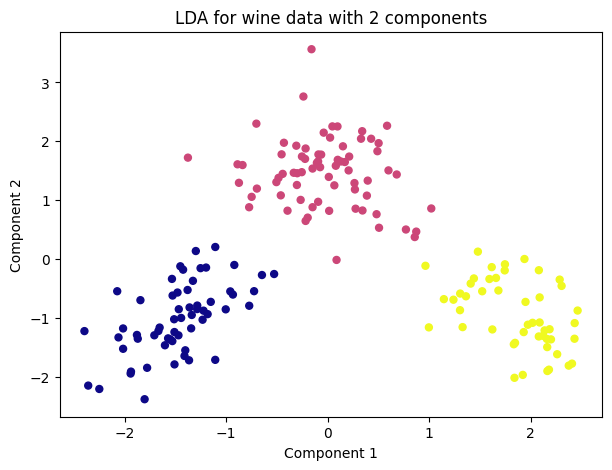

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=[7, 5])

plt.scatter(X_lda[:, 0], X_lda[:, 1], c=y, s=25, cmap="plasma")
plt.title("LDA for wine data with 2 components")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.savefig("LDA.png")

In [26]:
exp_var = sum(lda._get_explained_variance() * 100)
print("Variance explained:", exp_var)

Variance explained: 99.99999999999997


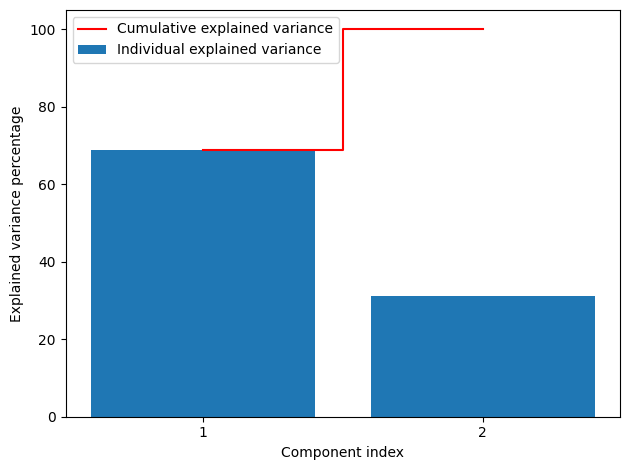

In [27]:
exp_var = lda._get_explained_variance() * 100
cum_exp_var = np.cumsum(exp_var)

plt.bar(range(1, 3), exp_var, align="center", label="Individual explained variance")

plt.step(
    range(1, 3),
    cum_exp_var,
    where="mid",
    label="Cumulative explained variance",
    color="red",
)

plt.ylabel("Explained variance percentage")
plt.xlabel("Component index")
plt.xticks(ticks=[1, 2])
plt.legend(loc="best")
plt.tight_layout()

plt.savefig("Barplot_LDA.png")